# 77장 · 컨테이너 이미지 digest와 롤백 기준

태그는 다른 이미지를 가리키도록 옮길 수 있습니다. 배포 후보를 구별하려면 이미지 내용에 대응하는 digest와 기능 검사 결과를 함께 봅니다.

배포 직전, 승인 화면에 적힌 이미지와 CI가 검사한 이미지의 이름은 같은데 digest가 다릅니다. 어떤 버전을 실제로 적용할지 정하지 않으면 되돌릴 때도 근거가 없습니다. 한 배포의 승인 조건과 실패 후 복구 경로를 로컬 기록으로 연습합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## 가변 태그와 콘텐츠 지문

CI는 검사한 소스와 이미지 후보를 함께 인계합니다. CD는 환경 승인과 현재 배포 상태를 확인하고 그 후보만 적용합니다. 여기서는 작은 바이트열의 SHA-256으로 서로 다른 내용을 구별합니다. 실제 레지스트리에서 받은 manifest digest를 대신하는 수업용 값입니다.

**이동하는 태그와 고정된 지문**　이름표가 다른 상자로 옮겨가는 동안 두 상자의 봉인을 보세요. 같은 태그로 다시 조회해도 같은 내용이라는 보장은 없습니다.

[웹 교재에서 열기](https://langchain-lecture.vercel.app/chapter77/index.html#concept-clip)


### 셀 01 · 태그와 해시 지문 비교

내용 한 줄이 바뀌었을 때 같은 승인값을 계속 쓸 수 있는지 확인하세요.


In [1]:
import hashlib
def digest(data):
    return "sha256:" + hashlib.sha256(data).hexdigest()
approved = digest(b"course-image B")
candidate = digest(b"course-image C")
print(approved == candidate)

False


False입니다. 승인 당시 검토한 내용과 현재 후보가 다르면 배포를 중단하고 새 후보의 검사 기록을 확인합니다.


### 과제 02 · 적용 전 조건 검사

승인한 digest와 후보 digest가 같고, 사람이 해당 환경의 적용을 승인했을 때만 배포를 허용하세요.


In [2]:
# can_apply(expected, candidate, approved_by_reviewer)를 작성하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>def can_apply(expected, candidate, approved_by_reviewer):
    return expected == candidate and approved_by_reviewer

print(can_apply(approved, candidate, True))</code></pre>
<p>실행 결과</p><pre><code>False</code></pre>
<p>사람이 승인했다고 표시해도 digest가 달라 False입니다. 수동 실행 버튼, 환경 승인, 후보 동일성은 각각 따로 확인합니다.</p>
</details>


## 기능 검사 실패 시 복구 후보 선택

아래 배포 대상은 수업용 메모리 사전입니다. 검사된 후보를 적용한 뒤 과제 안내 질문이 근거 ID를 유지하는지 확인합니다. 실패하면 보관한 이전 이미지로 돌립니다. DB 내용은 이 작업에서 바뀌지 않습니다.

<!-- lesson-visual detail-rollback -->
**HTTP 200을 받은 이미지 B가 왜 롤백될까요?**

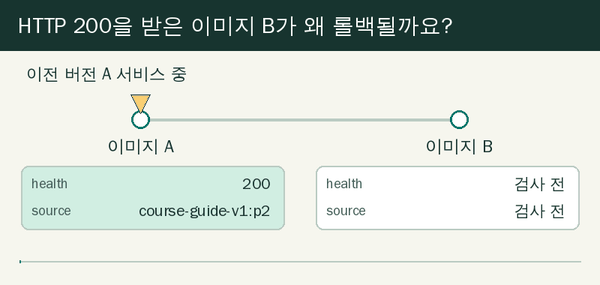

B는 HTTP 200을 반환하지만 출처가 None입니다. 검사 실패를 확인하면 active를 previous에 보관한 A로 되돌리고 A의 course-guide-v1:p2를 다시 읽습니다.
<!-- /lesson-visual detail-rollback -->


### 셀 03 · 검증 실패 시 롤백 판단

health가 정상이더라도 문서 근거가 사라진 후보를 어떻게 처리하는지 보세요.

앞 과제에서는 승인이 가리키는 후보와 적용할 후보가 달라서 멈췄습니다. 이번에는 B의 승인이 유효해 적용했고, 그 뒤 검사가 실패한 상황입니다. 되돌리기를 판단하는 시점이 다릅니다.


In [3]:
versions = {"A": {"health": 200, "source": "course-guide-v1:p2"},
            "B": {"health": 200, "source": None}}
deployment = {"active": "A"}
previous = deployment["active"]
deployment["active"] = "B"
current = versions[deployment["active"]]
if current["health"] != 200 or current["source"] != "course-guide-v1:p2":
    deployment["active"] = previous
print(deployment["active"], versions[deployment["active"]]["source"])

A course-guide-v1:p2


A와 원래 근거 ID가 보입니다. 이 결과는 복구 조건을 로컬에서 재현한 것입니다. 실제 배포에서는 이전 이미지와 현재 스키마가 호환되는지, 이전 버전에서도 같은 문서가 조회되는지 별도 검증해야 합니다.


## 돌아보기

운영 인계에는 적용한 후보 digest, 이전 digest, 확인한 요청과 결과, 적용하거나 되돌린 시각을 남깁니다. 상태를 읽을 수 없을 때 임의로 배포를 반복하지 않도록 담당자를 정하세요.

### 후보에서 확인 완료까지

**후보와 환경 확인**　같은 CI 기록·commit·digest·설정을 읽습니다.

```
후보 기록
```

**현재 상태 다시 확인**　동시 변경과 기준 상태의 차이를 찾습니다.

```
셀 01 · 승인 B와 후보 C의 digest 불일치 → 적용 중단
```

**검토한 이미지로 변경**　실제 경로·권한·효과를 기록합니다.

```
실행 관측
```

**서비스와 데이터 대조**　H1 정상/실패·전체 출처·기존 ID를 봅니다.

```
셀 03 · B에서 출처 누락 → A로 복원
다시 확인: course-guide-v1:p2
```
